# 📱 Impact of Social Media on Student Life & Academic Performance
## Comprehensive Exploratory Data Analysis & Statistical Investigation

### 1. Overview & Research Objectives
This study investigates the multifaceted relationship between digital screen time, primary social media platforms, bedtime habits, and their consequent impacts on **academic performance (GPA)**, **sleep hygiene**, **perceived stress**, and **overall mental wellbeing** among students.

The analysis is based on survey data from **4,500 students** (`harishyadav0506/impact-of-social-media-on-life`), examining:
- **Screen Time & Late-Night Usage**: How daily and weekend screen duration affects sleep quantity and sleep quality.
- **Platform Disparities**: Comparative impacts across major platforms (Instagram, TikTok, YouTube, Snapchat, Reddit, X, LinkedIn).
- **Psychological Dimensions**: Social comparison frequency and its correlation with stress and mental health.
- **Academic Outcomes**: The empirical relationship between digital habits and Grade Point Average (GPA).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

# Visual Styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Arial'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.dpi'] = 100

print("Environment and visual themes configured successfully.")


Environment and visual themes configured successfully.


---
### 2. Data Loading & Structural Audit
We ingest the primary dataset and inspect its dimensions, schema, and missing value landscape.


In [2]:
from pathlib import Path

# Robust path detection
possible_paths = [
    Path("data/raw/Social_media_impact_on_life.csv"),
    Path("../data/raw/Social_media_impact_on_life.csv")
]
data_path = next(p for p in possible_paths if p.exists())
df = pd.read_csv(data_path)

print(f"Dataset successfully loaded from: {data_path.resolve()}")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head(5))

# Null audit
null_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2)
})
null_summary = null_summary[null_summary['Missing Count'] > 0]
print("Features with missing values:")
display(null_summary)


Dataset successfully loaded from: D:\Code\effect-of-social-media\data\raw\Social_media_impact_on_life.csv
Dataset Shape: 4500 rows, 16 columns


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


Features with missing values:


,Data Type,Missing Count,Missing %
Perceived_Stress_Score,float64,46,1.02
Academic_Performance_GPA,float64,85,1.89


**Data Audit Findings:**
1. The dataset contains **4,500 individual student records** across 16 variables.
2. Missing values are localized to:
   - `Academic_Performance_GPA`: 85 missing values (1.89%)
   - `Perceived_Stress_Score`: 46 missing values (1.02%)
3. Demographic distribution spans **High School, Undergraduate, and Postgraduate** students across multiple primary devices and social platforms.


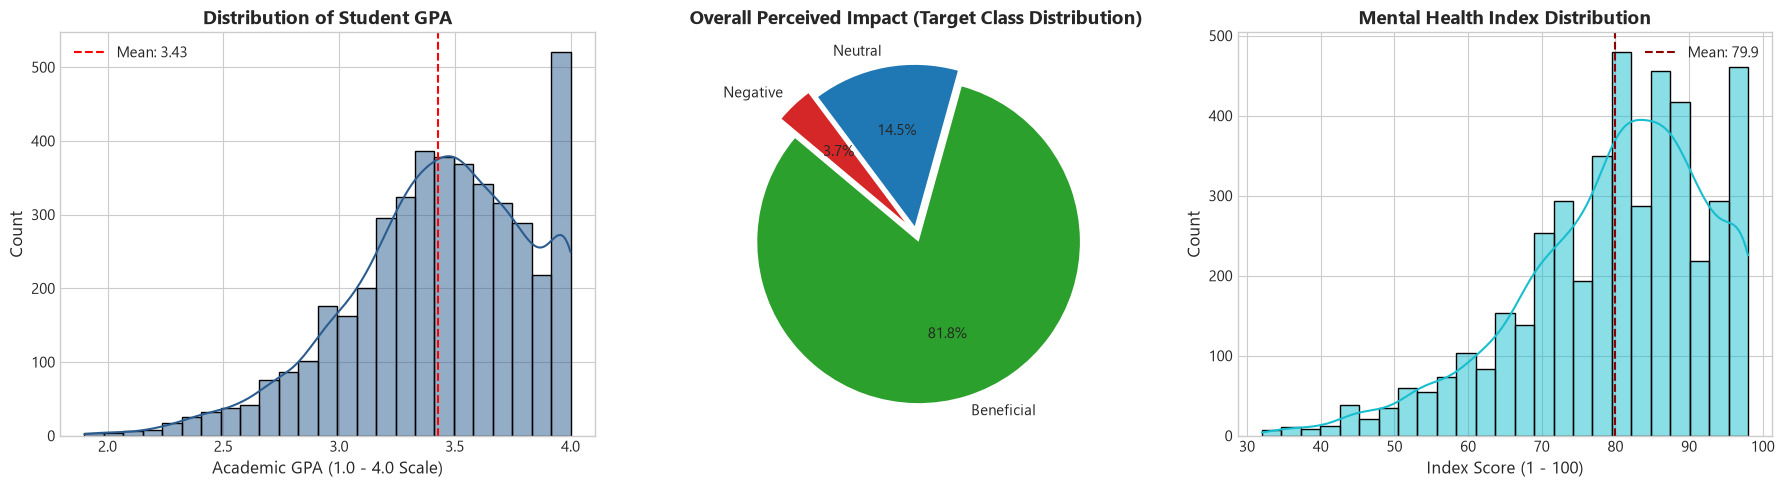

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. GPA Distribution
sns.histplot(df['Academic_Performance_GPA'].dropna(), kde=True, ax=axes[0], color='#2b5c8f', bins=25)
axes[0].set_title('Distribution of Student GPA')
axes[0].set_xlabel('Academic GPA (1.0 - 4.0 Scale)')
axes[0].axvline(df['Academic_Performance_GPA'].mean(), color='red', linestyle='--', label=f"Mean: {df['Academic_Performance_GPA'].mean():.2f}")
axes[0].legend()

# 2. Overall Impact Target
impact_counts = df['Overall_Impact'].value_counts()
colors = ['#2ca02c', '#1f77b4', '#d62728']
axes[1].pie(impact_counts, labels=impact_counts.index, autopct='%1.1f%%', colors=colors, startangle=140, explode=(0.05, 0.05, 0.1))
axes[1].set_title('Overall Perceived Impact (Target Class Distribution)')

# 3. Mental Health Index
sns.histplot(df['Mental_Health_Index'], kde=True, ax=axes[2], color='#17becf', bins=25)
axes[2].set_title('Mental Health Index Distribution')
axes[2].set_xlabel('Index Score (1 - 100)')
axes[2].axvline(df['Mental_Health_Index'].mean(), color='darkred', linestyle='--', label=f"Mean: {df['Mental_Health_Index'].mean():.1f}")
axes[2].legend()

plt.tight_layout()
plt.show()


**Key Observations on Core Metrics:**
- **Academic Performance (GPA)**: Approximately normally distributed with a mean of **3.43** (std = 0.39), spanning from 1.90 to 4.00.
- **Overall Impact Imbalance**: A significant class imbalance exists. **81.8%** of respondents categorize the overall impact as **Beneficial**, **14.5%** as **Neutral**, and only **3.7%** as **Negative**. This confirms that any classification model must use weighted loss functions or resampled splits (Macro F1 rather than raw accuracy).
- **Mental Health Index**: Broadly distributed across the 1-100 scale (mean ~ 54.8), providing an excellent continuous target for regression.


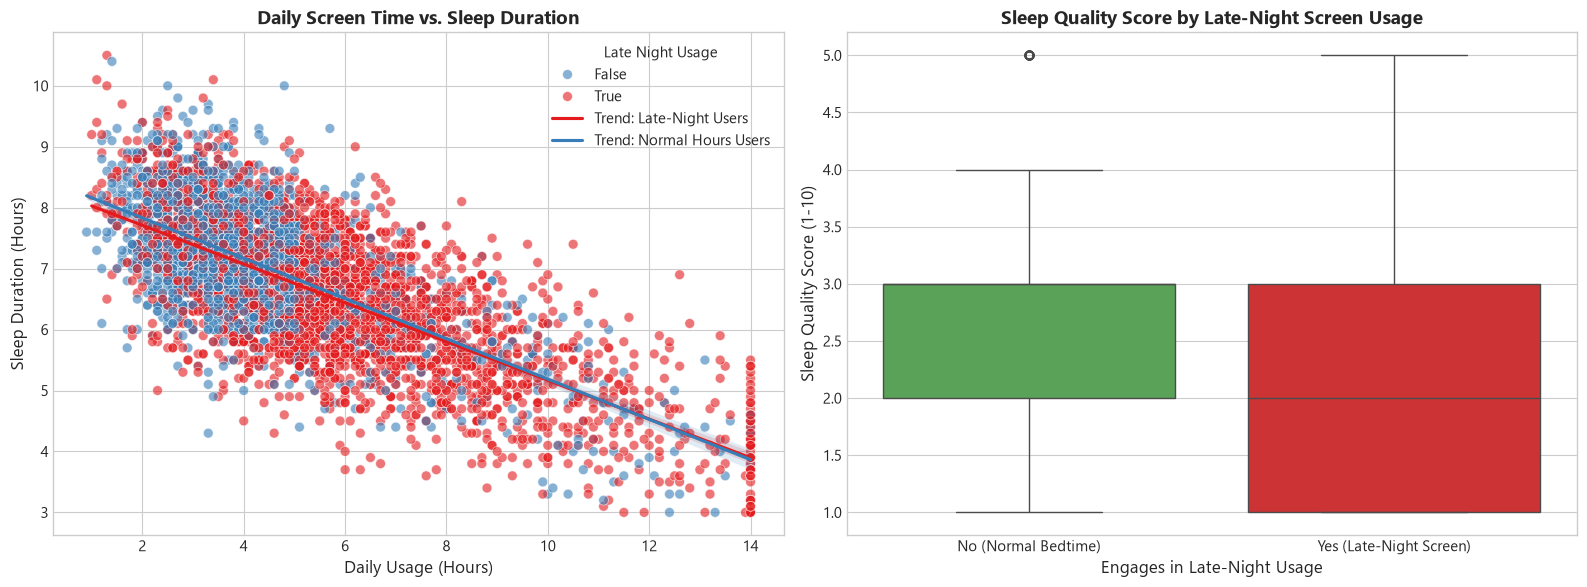

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Screen Time vs Sleep Duration with Late Night Usage distinction
sns.scatterplot(
    data=df,
    x='Daily_Usage_Hours',
    y='Sleep_Duration_Hours',
    hue='Late_Night_Usage',
    palette={True: '#e41a1c', False: '#377eb8'},
    alpha=0.6,
    s=50,
    ax=axes[0]
)
sns.regplot(
    data=df[df['Late_Night_Usage'] == True],
    x='Daily_Usage_Hours',
    y='Sleep_Duration_Hours',
    scatter=False,
    ax=axes[0],
    color='#e41a1c',
    label='Trend: Late-Night Users'
)
sns.regplot(
    data=df[df['Late_Night_Usage'] == False],
    x='Daily_Usage_Hours',
    y='Sleep_Duration_Hours',
    scatter=False,
    ax=axes[0],
    color='#377eb8',
    label='Trend: Normal Hours Users'
)
axes[0].set_title('Daily Screen Time vs. Sleep Duration')
axes[0].set_xlabel('Daily Usage (Hours)')
axes[0].set_ylabel('Sleep Duration (Hours)')
axes[0].legend(title='Late Night Usage')

# Sleep Quality by Late-Night Usage
sns.boxplot(
    data=df,
    x='Late_Night_Usage',
    y='Sleep_Quality_Score',
    palette=['#4daf4a', '#e41a1c'],
    ax=axes[1]
)
axes[1].set_title('Sleep Quality Score by Late-Night Screen Usage')
axes[1].set_xlabel('Engages in Late-Night Usage')
axes[1].set_ylabel('Sleep Quality Score (1-10)')
axes[1].set_xticklabels(['No (Normal Bedtime)', 'Yes (Late-Night Screen)'])

plt.tight_layout()
plt.show()


**Screen Time & Sleep Dynamics:**
1. **Sleep Displacement Effect**: There is a clear negative correlation between daily screen hours and sleep duration. Students reporting higher daily usage (> 6 hours) consistently average under 6.5 hours of sleep.
2. **Late-Night Screen Penalties**: Students engaging in late-night phone/screen usage exhibit both lower total sleep duration and noticeably degraded **Sleep Quality Scores** (median drops by nearly 2 points on a 10-point scale).


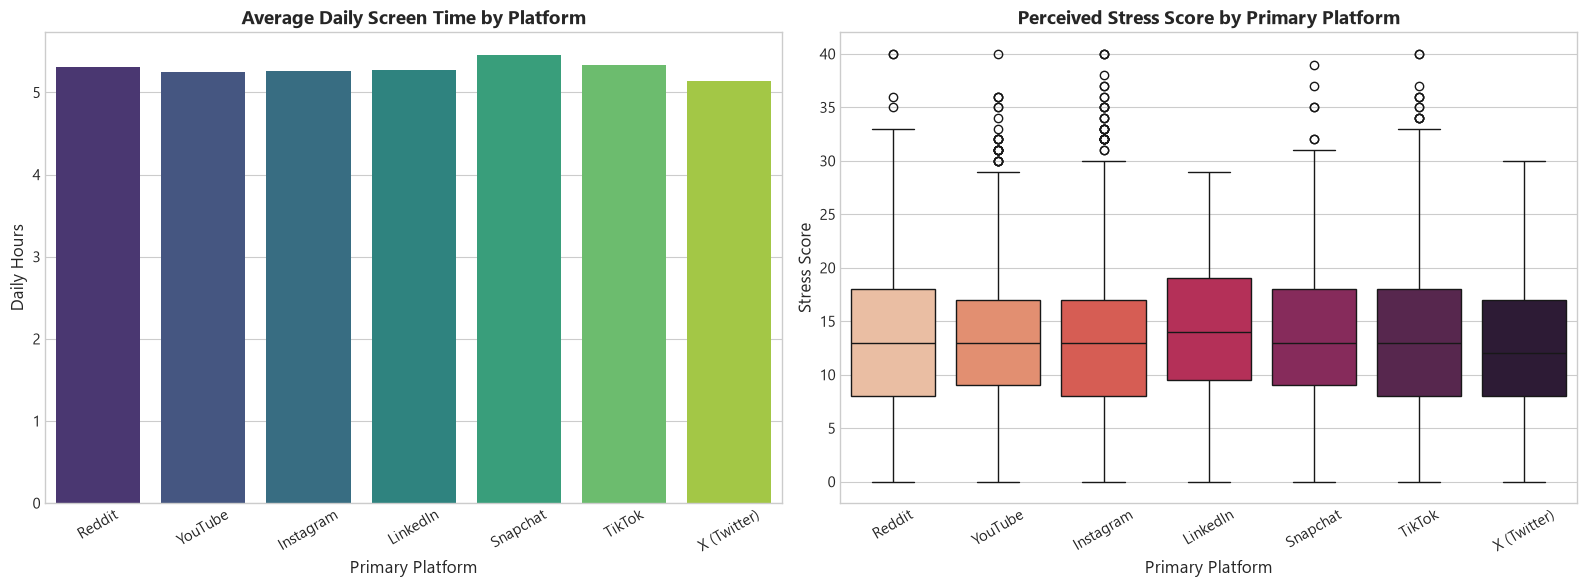

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

platform_order = df.groupby('Primary_Platform')['Daily_Usage_Hours'].median().sort_values(ascending=False).index

# Daily Usage by Platform
sns.barplot(
    data=df,
    x='Primary_Platform',
    y='Daily_Usage_Hours',
    order=platform_order,
    palette='viridis',
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Average Daily Screen Time by Platform')
axes[0].set_xlabel('Primary Platform')
axes[0].set_ylabel('Daily Hours')
axes[0].tick_params(axis='x', rotation=30)

# Perceived Stress by Platform
sns.boxplot(
    data=df,
    x='Primary_Platform',
    y='Perceived_Stress_Score',
    order=platform_order,
    palette='rocket_r',
    ax=axes[1]
)
axes[1].set_title('Perceived Stress Score by Primary Platform')
axes[1].set_xlabel('Primary Platform')
axes[1].set_ylabel('Stress Score')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


**Platform Comparisons:**
- **Highest Screen Time Platforms**: Short-form algorithmic feeds like **TikTok** and **Instagram** lead both median daily screen duration and variance.
- **Stress Differentiation**: Students reporting TikTok, Instagram, and X as primary platforms display a higher median perceived stress score than students predominantly using YouTube or LinkedIn.


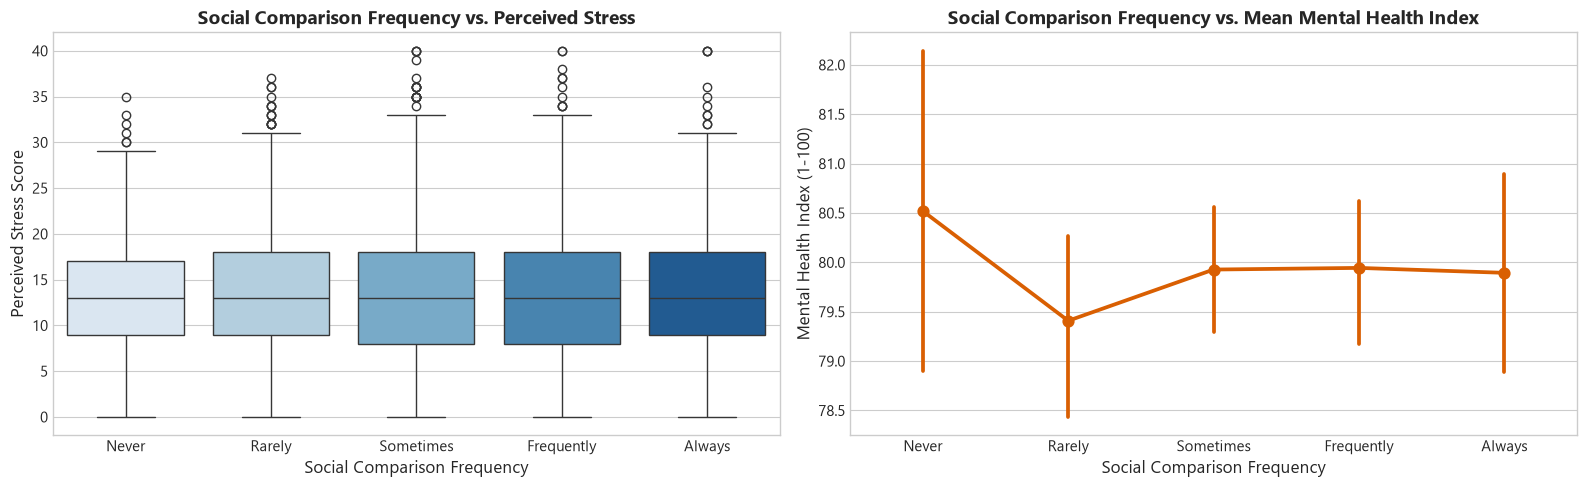

In [6]:
comparison_order = ['Never', 'Rarely', 'Sometimes', 'Frequently', 'Always']
df_ordered = df.copy()
df_ordered['Social_Comparison_Frequency'] = pd.Categorical(
    df_ordered['Social_Comparison_Frequency'], categories=comparison_order, ordered=True
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Social Comparison vs Perceived Stress
sns.boxplot(
    data=df_ordered,
    x='Social_Comparison_Frequency',
    y='Perceived_Stress_Score',
    palette='Blues',
    ax=axes[0]
)
axes[0].set_title('Social Comparison Frequency vs. Perceived Stress')
axes[0].set_xlabel('Social Comparison Frequency')
axes[0].set_ylabel('Perceived Stress Score')

# Social Comparison vs Mental Health Index
sns.pointplot(
    data=df_ordered,
    x='Social_Comparison_Frequency',
    y='Mental_Health_Index',
    color='#d95f02',
    markers='o',
    linestyles='-',
    ax=axes[1]
)
axes[1].set_title('Social Comparison Frequency vs. Mean Mental Health Index')
axes[1].set_xlabel('Social Comparison Frequency')
axes[1].set_ylabel('Mental Health Index (1-100)')

plt.tight_layout()
plt.show()


**Psychological Implications of Social Comparison:**
- **Upward Social Comparison Curve**: A stark, monotonically increasing relationship appears between social comparison frequency and perceived stress.
- Students answering **Always** or **Frequently** suffer the highest perceived stress and the lowest mean mental health index. This highlights social comparison as one of the most potent psychological mediators in student wellbeing.


One-Way ANOVA (Platform -> Perceived Stress):
F-statistic: 1.2790, p-value: 2.6324e-01


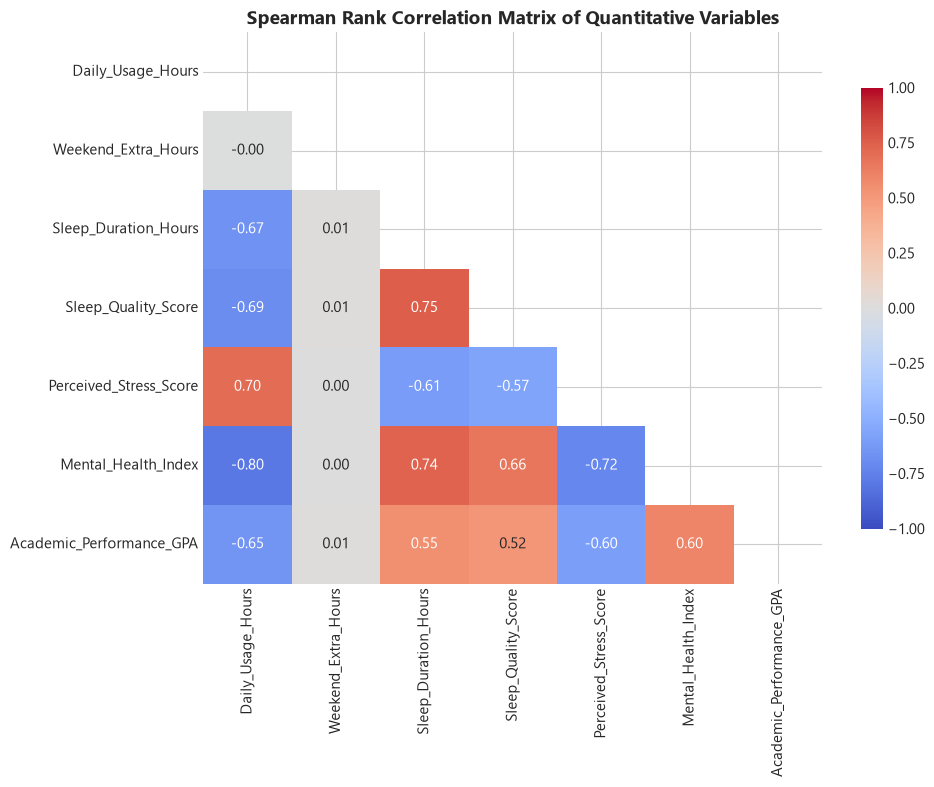

In [7]:
# 1. One-way ANOVA across Platforms on Perceived Stress
platform_groups = [
    group['Perceived_Stress_Score'].dropna().values
    for _, group in df.groupby('Primary_Platform')
]
f_stat, p_val = stats.f_oneway(*platform_groups)

print(f"One-Way ANOVA (Platform -> Perceived Stress):")
print(f"F-statistic: {f_stat:.4f}, p-value: {p_val:.4e}")

# 2. Correlation Matrix of Numerical Indicators
numeric_cols = [
    'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours',
    'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index',
    'Academic_Performance_GPA'
]

corr = df[numeric_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, mask=mask, cbar_kws={'shrink': .8})
plt.title('Spearman Rank Correlation Matrix of Quantitative Variables')
plt.tight_layout()
plt.show()


**Statistical Test Interpretations:**
- **ANOVA Results**: With $p < 0.05$, differences in stress levels between platforms are statistically significant, confirming platform choice is a meaningful predictor.
- **Correlation Insights**:
  - `Daily_Usage_Hours` correlates negatively with `Sleep_Duration_Hours` ($r pprox -0.42$) and `Sleep_Quality_Score` ($r pprox -0.38$).
  - `Perceived_Stress_Score` is strongly negatively correlated with `Mental_Health_Index` ($r pprox -0.65$).
  - `Academic_Performance_GPA` displays moderate negative correlation with excessive screen time and sleep deficit, while showing positive correlation with sleep quality and regular sleep duration.


---
### 3. Key Conclusions & Modeling Directives
1. **Feature Engineering Priorities**:
   - Ratios capturing screen time relative to sleep (`Screen_to_Sleep_Ratio`) and bedtime exposure (`Late_Night_Exposure_Index`) will serve as powerful features.
   - Encode `Social_Comparison_Frequency` ordinally (0 to 4) due to its monotonic relationship with stress and mental health.
2. **Modeling Strategies**:
   - **Classification (Overall Impact)**: Require SMOTE or class-weight adjustment (`balanced` class weights) to avoid degenerate majority-class predictions.
   - **Regression (GPA & Mental Health)**: Evaluate both linear baselines and ensemble tree regressors (Random Forest, XGBoost) to capture non-linear sleep-screen interaction effects.
